# Human PBMCs

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2022-7-16
> - Modified: 2024-8-11
---

> - [10k Human PBMCs, 3' v3.1, Chromium X](https://www.10xgenomics.com/cn/datasets/10k-human-pbmcs-3-ht-v3-1-chromium-x-3-1-high)
> - Organism: Homo sapiens
> - Tissue: PBMCs
> - 10X 3' V3.1 scRNA-seq
> - 2021-09-15

---

# Experimental Design

| Sample | Tissue | Full name | Gender | Age | Disease status |
| - | - | - | - | - | - |
| Donor | PBMCs | Peripheral blood mononuclear cells | Female | 25-30 | Healthy |

> - Chromium Single Cell 3' Reagent Kits (v3.1 Chemistry Dual Index, CG000315 Rev C)
> - Chromium X
>     - input: ~ 16,000 cells
>     - recovered: 11,996 cells
> - Illumina NovaSeq 6000
> - Cell Ranger v6.1.0 with --expect-cells = 10000

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [ ]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv3_10k"

In [2]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(data_dir, "visualization"), 
           recursive = TRUE, showWarnings = FALSE)

In [3]:
scrna <- file.path(
    data_dir, "matrix", "filtered_feature_bc_matrix.h5") |> 
    Read10X_h5() |>
    CreateSeuratObject(project = "PBMCs", min.cells = 3)
# scrna <- file.path(
#     data_dir, "matrix", "filtered_feature_bc_matrix") |> 
#     Read10X() |>
#     CreateSeuratObject(project = "PBMCs", min.cells = 3)

An object of class Seurat 
22302 features across 11996 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)

In [ ]:
scrna

# 2. Quality Control

## 1). Calculate Metrics

In [ ]:
# Mitochondrial genes
mt <- "(?i)^MT-"
scrna[["percent.mt"]] <- PercentageFeatureSet(scrna, pattern = mt)

In [5]:
# Ribosomal genes
rp <- "(?i)^(MRP|RP[LS])"
scrna[["percent.rp"]] <- PercentageFeatureSet(scrna, pattern = rp)

In [6]:
# Hemoglobin genes
hb <- "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)"
scrna[["percent.hb"]] <- PercentageFeatureSet(scrna, pattern = hb)

In [7]:
head(scrna@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.rp,percent.hb
,<fct>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
AAACCCAAGGCCCAAA-1,PBMCs,12143,3022,6.406983,19.86330,0
AAACCCAAGTAATACG-1,PBMCs,7810,2666,6.312420,13.22663,0
AAACCCAAGTCACACT-1,PBMCs,9741,2934,8.643876,18.11929,0
AAACCCACAAAGCGTG-1,PBMCs,5561,1525,5.196907,45.87304,0
AAACCCACAATCGAAA-1,PBMCs,7398,2077,8.867261,35.53663,0
AAACCCACAGATCACT-1,PBMCs,4592,1549,8.275261,32.75261,0


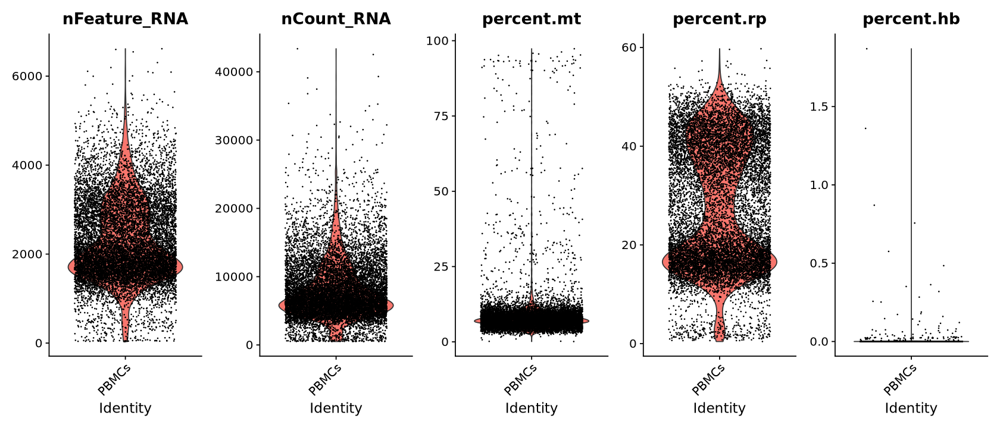

In [8]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(scrna,
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.1, ncol = 5) + 
    NoLegend()

In [9]:
p1 <- FeatureScatter(scrna, feature1 = "nCount_RNA", feature2 = "percent.mt")
p2 <- FeatureScatter(scrna, feature1 = "nCount_RNA", feature2 = "nFeature_RNA")

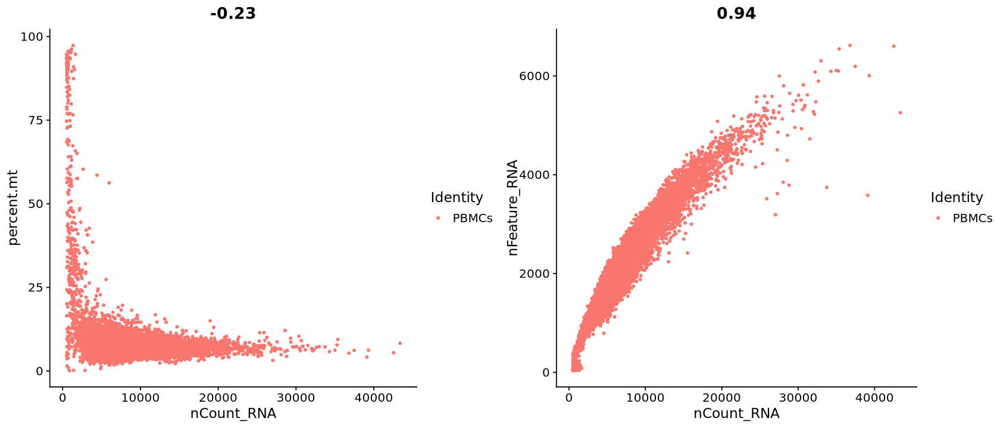

In [10]:
options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

## Remove doublets

### Filtering low-coverage cells

Remove empty droplets and very low coverage cells to avoid affecting double cell recognition

[DropletUtils](https://github.com/MarioniLab/DropletUtils): Loading from count matrices or molecule information files, identification of cells from empty droplets, removal of barcode-swapped pseudo-cells, and downsampling of the count matrix.

In [11]:
# Standard Seurat workflow
standard_preprocessing <- function(
    seurat, method = c("lognorm", "sctransform"), 
    ndim = 10, resolution = 0.5) {
    
    method <- match.arg(method)

    if (method == "lognorm") {
        # LogNormalize
        seurat <- NormalizeData(seurat, verbose = FALSE) |>
            FindVariableFeatures(verbose = FALSE) |>
            ScaleData(verbose = FALSE) |>
            RunPCA(verbose = FALSE) |>
            RunUMAP(dims = 1:ndim, verbose = FALSE) |>
            RunTSNE(dims = 1:ndim, verbose = FALSE) |>
            FindNeighbors(dims = 1:ndim, verbose = FALSE) |>
            FindClusters(resolution = resolution, verbose = FALSE)
        message("Completed LogNormalize workflow.")
    } else if (method == "sctransform") {
        # sctransform (very slow)
        seurat <- SCTransform(seurat, verbose = FALSE) |>
            RunPCA(verbose = FALSE) |>
            RunUMAP(dims = 1:ndim, verbose = FALSE) |>
            RunTSNE(dims = 1:ndim, verbose = FALSE) |>
            FindNeighbors(dims = 1:ndim, verbose = FALSE) |>
            FindClusters(resolution = resolution, verbose = FALSE)
        # DefaultAssay(seurat) <- "RNA"
        message("Completed SCTransform workflow.")
    }
    return(seurat)
}

In [12]:
sc.temp <- standard_preprocessing(scrna)
sc.temp

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
Completed LogNormalize workflow.



An object of class Seurat 
22302 features across 11996 samples within 1 assay 
Active assay: RNA (22302 features, 2000 variable features)
 3 dimensional reductions calculated: pca, umap, tsne

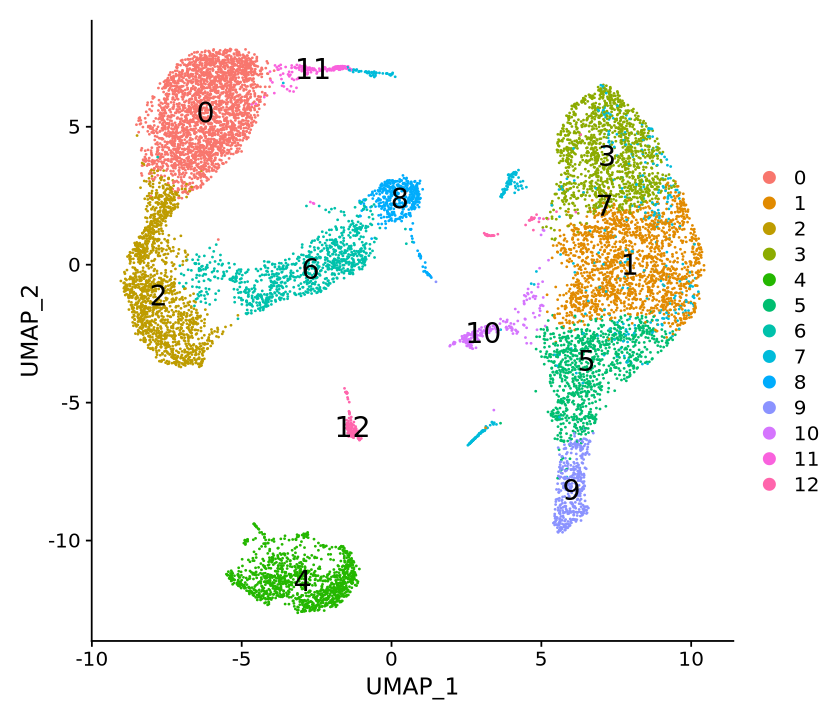

In [13]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(
    sc.temp, reduction = "umap",
    label = TRUE, label.size = 6)

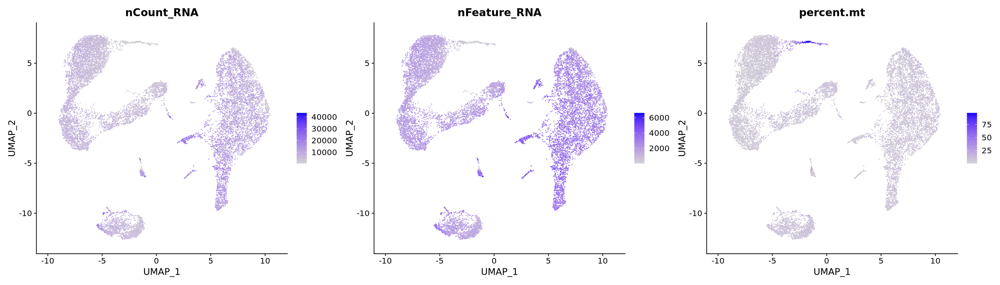

In [14]:
options(repr.plot.width = 21, repr.plot.height = 6)
FeaturePlot(
    sc.temp, reduction = "umap", ncol = 3,
    features = c("nCount_RNA", "nFeature_RNA", "percent.mt"))

In [15]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 200 & percent.mt < 20)
scrna

An object of class Seurat 
22302 features across 11694 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)

In [16]:
sc.temp <- standard_preprocessing(scrna)

Completed LogNormalize workflow.



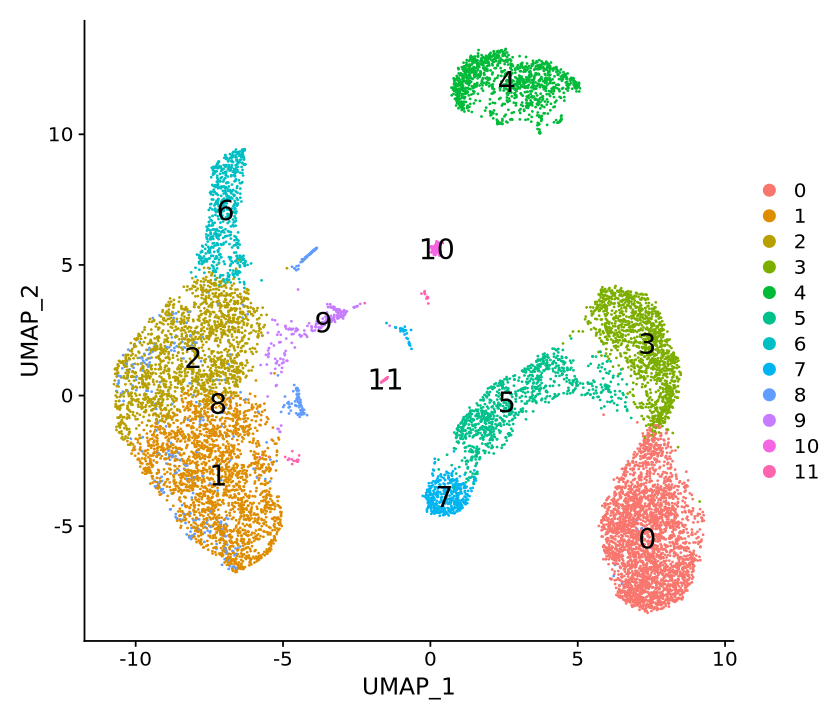

In [17]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(
    sc.temp, reduction = "umap",
    label = TRUE, label.size = 6)

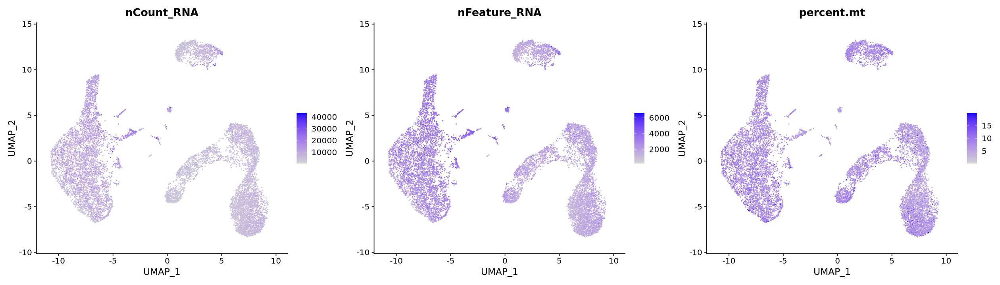

In [18]:
options(repr.plot.width = 21, repr.plot.height = 6)
FeaturePlot(
    sc.temp, reduction = "umap", ncol = 3,
    features = c("nCount_RNA", "nFeature_RNA", "percent.mt"))

### [DoubletFinder](https://github.com/chris-mcginnis-ucsf/DoubletFinder)

1. Generate artificial doublets from existing scRNA-seq data
2. Pre-process merged real-artificial data
3. Perform PCA and use the PC distance matrix to find each cell's proportion of artificial k nearest neighbors (pANN)
4. Rank order and threshold pANN values according to the expected number of doublets

- McGinnis CS, Murrow LM, Gartner ZJ. DoubletFinder: Doublet Detection in Single-Cell RNA Sequencing Data Using Artificial Nearest Neighbors. Cell Syst. 2019 Apr 24;8(4):329-337.e4. doi: 10.1016/j.cels.2019.03.003.

In [19]:
suppressPackageStartupMessages(library(DoubletFinder))

In [20]:
# sc.temp <- standard_preprocessing(scrna)
sc.temp

An object of class Seurat 
22302 features across 11694 samples within 1 assay 
Active assay: RNA (22302 features, 2000 variable features)
 3 dimensional reductions calculated: pca, umap, tsne

In [21]:
# Performs pN-pK parameter sweeps on a 10,000-cell subset of
# a pre-processed Seurat object.
set.seed(1234)
sweep.res.list <- paramSweep_v3(sc.temp, PCs = 1:10, sct = FALSE)

Loading required package: fields

Loading required package: spam

Spam version 2.11-1 (2025-01-20) is loaded.
Type 'help( Spam)' or 'demo( spam)' for a short introduction 
and overview of this package.
Help for individual functions is also obtained by adding the
suffix '.spam' to the function name, e.g. 'help( chol.spam)'.


Attaching package: ‘spam’


The following objects are masked from ‘package:base’:

    backsolve, forwardsolve


Loading required package: viridisLite

Loading required package: RColorBrewer


Try help(fields) to get started.



[1] "Creating artificial doublets for pN = 5%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.001..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."
[1] "Creating artificial doublets for pN = 10%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.001..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."
[1] "Creating artificial doublets for pN = 15%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


... (4 outputs left out)

Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.001..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."
[1] "Creating artificial doublets for pN = 30%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.001..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


In [22]:
# Summarizes results from doubletFinder::ParamSweep, 
# computing the bimodality coefficient across pN and pK parameter space.

# pK Identification (no ground-truth)
sweep.stats <- summarizeSweep(sweep.res.list, GT = FALSE)

# # pK Identification (ground-truth)
# gt.calls <- temp@meta.data[rownames(sweep.res.list[[1]]), "GT"].
# # When GT = TRUE, the function involves random sampling
# set.seed(1234)
# sweep.stats <- summarizeSweep(sweep.res.list, GT = TRUE, GT.calls = gt.calls)

Loading required package: KernSmooth

KernSmooth 2.23 loaded
Copyright M. P. Wand 1997-2009

Loading required package: ROCR



NULL


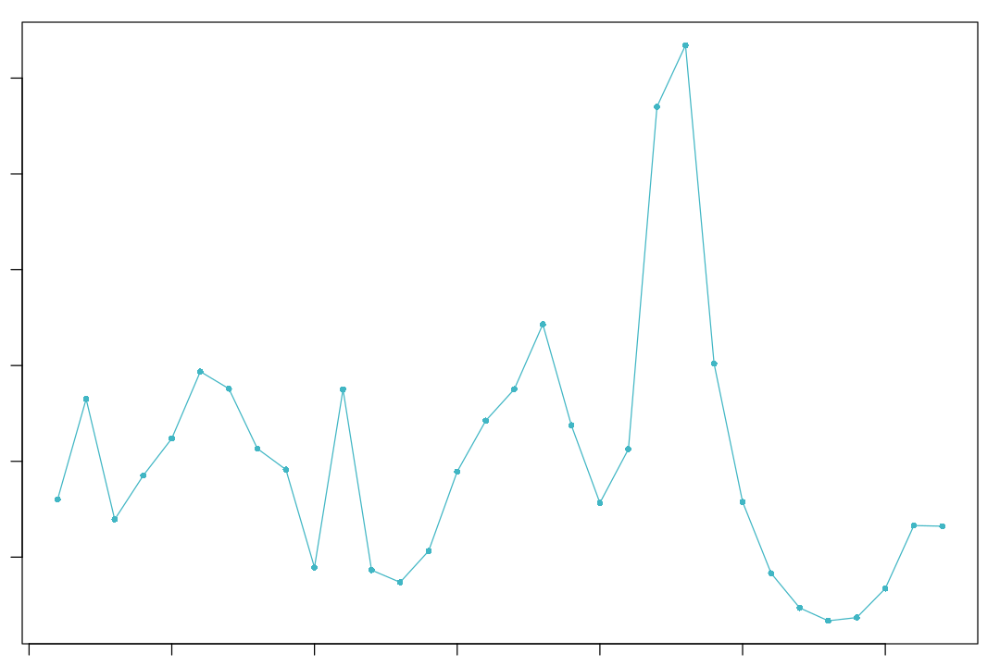

In [23]:
options(repr.plot.width = 9, repr.plot.height = 6)
# Computes and visualizes the mean-variance normalized
# bimodality coefficient (BCmvn) score for each pK value
# tested during doubletFinder_ParamSweep.
bcmvn <- find.pK(sweep.stats)

In [24]:
optimal.pK <- bcmvn$pK[which.max(bcmvn$BCmetric)] |> 
    as.vector() |> as.numeric()
message("optimal pK: ", optimal.pK)

optimal pK: 0.21



In [25]:
# Homotypic Doublet Proportion Estimate
# Leverages user-provided cell annotations to model 
# the proportion of homotypic doublets.
homotypic.prop <- modelHomotypic(sc.temp$seurat_clusters)

nCell <- length(Cells(sc.temp))
nExp <- round(nCell / 1000 * 0.008 * nCell)
nExp.adj <- round(nExp * (1 - homotypic.prop))

message("Estimated expected doublets (nExp): ", nExp.adj)

Estimated expected doublets (nExp): 937



In [26]:
set.seed(1234)
sc.temp <- doubletFinder_v3(
    sc.temp, PCs = 1:10, pN = 0.25, 
    pK = optimal.pK, nExp = nExp.adj)

[1] "Creating 3898 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Computing pANN..."
[1] "Classifying doublets.."


In [27]:
old_col <- paste(c("pANN", "DF.classifications"),
                 0.25, optimal.pK, nExp.adj, sep = "_")
scrna$DoubletFinder.pANN <- sc.temp@meta.data[, old_col[1]]
scrna$DoubletFinder.class <- sc.temp@meta.data[, old_col[2]] |> 
    factor(levels = c("Singlet", "Doublet"))

In [28]:
table(scrna$DoubletFinder.class)


Singlet Doublet 
  10757     937 

### [scDblFinder](https://github.com/plger/scDblFinder)

scDblFinder() has two main modes of operation: cluster-based or not. Both perform quite well (see Germain et al., 2021). In general, we recommend the cluster-based approach in datasets with a very clear cluster structure, and the random approach in more complex datasets.

1. Reducing and clustering the data
2. Generating artificial doublets
3. Examining the k-nearest neighbors (kNN) of each cell
4. Training a classifier
5. Thresholding
6. Doublet origins and enrichments

- Germain PL, Lun A, Garcia Meixide C et al. Doublet identification in single-cell sequencing data using scDblFinder [version 2; peer review: 2 approved]. F1000Research 2022, 10:979 (https://doi.org/10.12688/f1000research.73600.2)

In [29]:
suppressPackageStartupMessages(library(scDblFinder))

In [30]:
# sce <- standard_preprocessing(scrna) |>
#     as.SingleCellExperiment()
sce <- as.SingleCellExperiment(sc.temp)
sce

class: SingleCellExperiment 
dim: 22302 11694 
metadata(0):
assays(2): counts logcounts
rownames(22302): AL627309.1 AL627309.3 ... AC233755.1 AC007325.4
rowData names(0):
colnames(11694): AAACCCAAGGCCCAAA-1 AAACCCAAGTAATACG-1 ...
  TTTGTTGTCTACACAG-1 TTTGTTGTCTCATTAC-1
colData names(11): orig.ident nCount_RNA ...
  DF.classifications_0.25_0.21_937 ident
reducedDimNames(3): PCA UMAP TSNE
mainExpName: RNA
altExpNames(0):

In [32]:
set.seed(1234)
# # random approach in more complex datasets.
# sce <- scDblFinder(sce, verbose = FALSE)
# cluster-based approach in datasets with a very clear cluster structure.
sce <- scDblFinder(sce, clusters = "seurat_clusters", verbose = FALSE)
sce

In [38]:
# # normal scater-based normalization and PCA
# set.seed(1234)
# sce <- scDblFinder(
#     GetAssayData(sc.temp, slot = "counts"),
#     clusters = Idents(sc.temp), verbose = FALSE)

Assuming the input to be a matrix of counts or expected counts.



: 

: 

In [ ]:
scrna$scDblFinder.score <- colData(sce)$scDblFinder.score
scrna$scDblFinder.class <- colData(sce)$scDblFinder.class

In [ ]:
table(scrna$scDblFinder.class)

### Filtering doublet cells

In [32]:
table(scDblFinder = scrna$scDblFinder.class, 
      DoubletFinder = scrna$DoubletFinder.class)

           DoubletFinder
scDblFinder Singlet Doublet
    singlet   10334     546
    doublet     423     391

In [33]:
sc.temp <- standard_preprocessing(scrna)

Completed LogNormalize workflow.



In [34]:
p1 <- VlnPlot(sc.temp, layer = "counts", 
              group.by = "scDblFinder.class", 
              features = c("nCount_RNA", "nFeature_RNA"), 
              pt.size = 0, ncol = 2) +
    NoLegend()
p2 <- VlnPlot(sc.temp, layer = "counts", 
              group.by = "DoubletFinder.class",
              features = c("nCount_RNA", "nFeature_RNA"), 
              pt.size = 0, ncol = 2) +
    NoLegend()

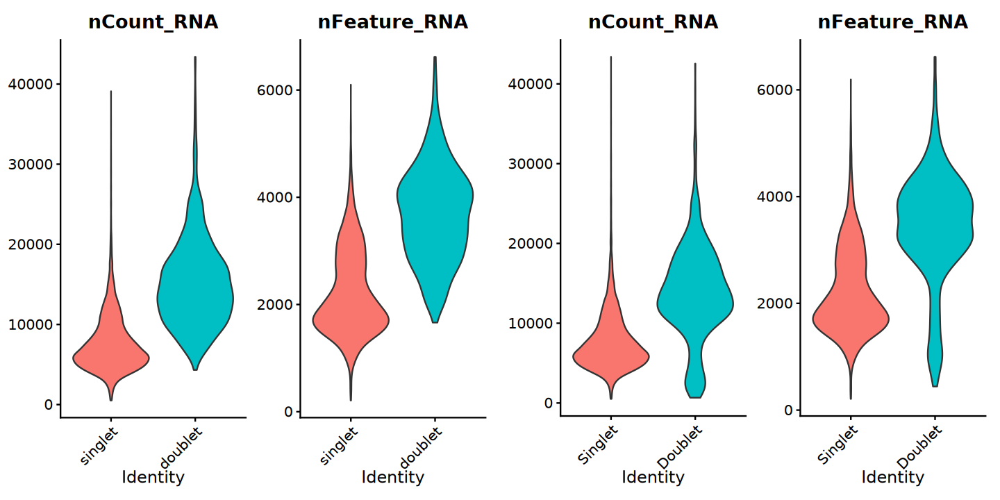

In [35]:
options(repr.plot.width = 12, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

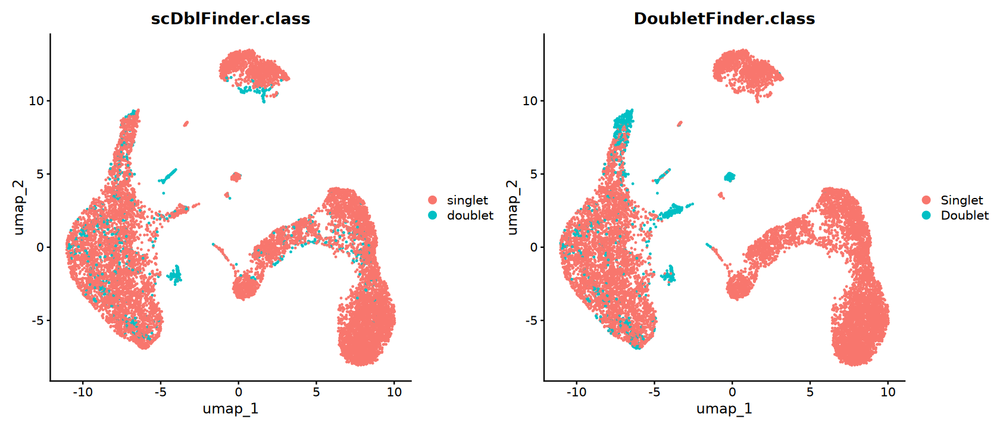

In [36]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(
    sc.temp, reduction = "umap", ncol = 2,
    group.by = c("scDblFinder.class", "DoubletFinder.class"))

In [37]:
Idents(sc.temp) <- apply(
    sc.temp@meta.data[, c("scDblFinder.class", "DoubletFinder.class")],
    1, function(x) paste(x, collapse = "_"))

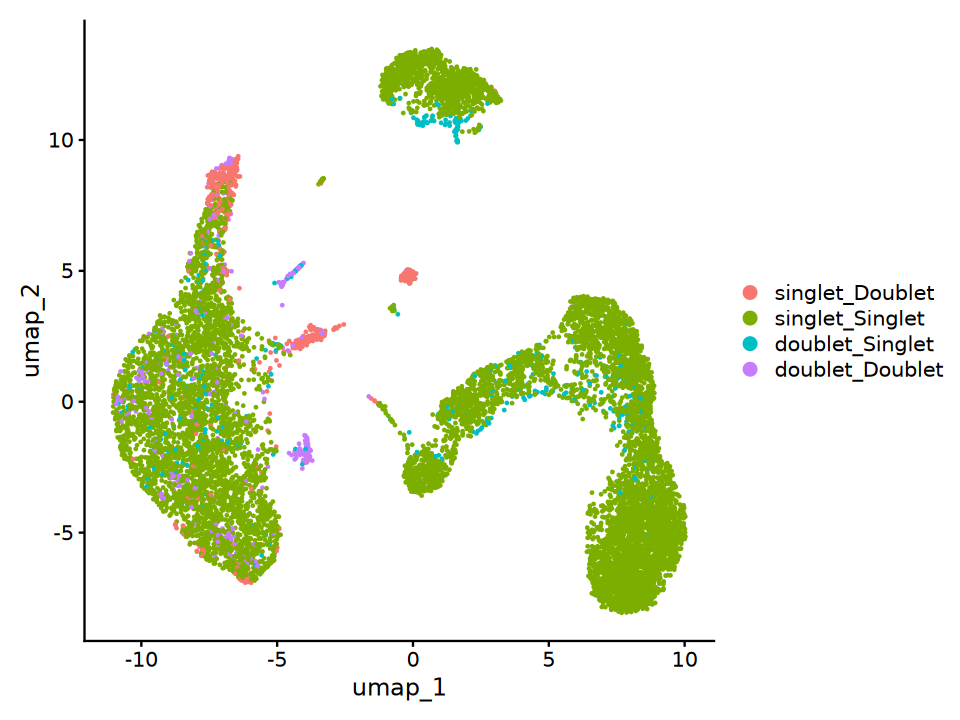

In [38]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap")

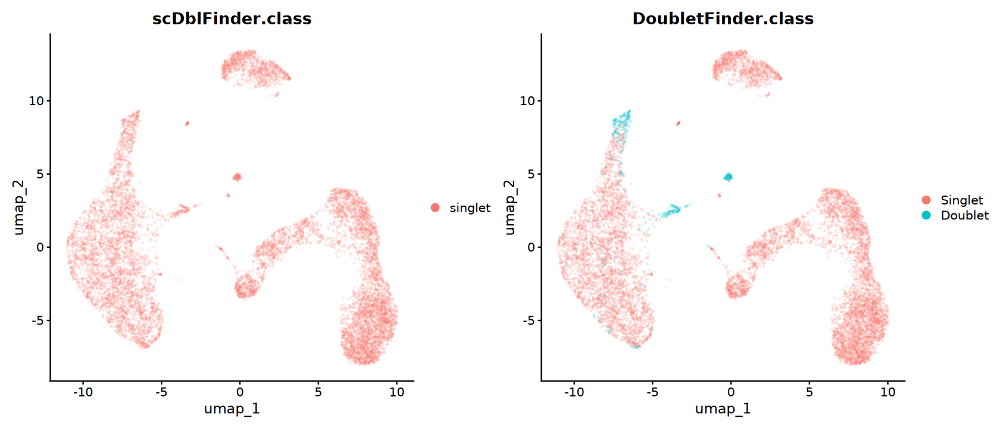

In [39]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(
    subset(sc.temp, subset = scDblFinder.class == "singlet"),
    reduction = "umap", alpha = 0.1, ncol = 2,
    group.by = c("scDblFinder.class", "DoubletFinder.class"))

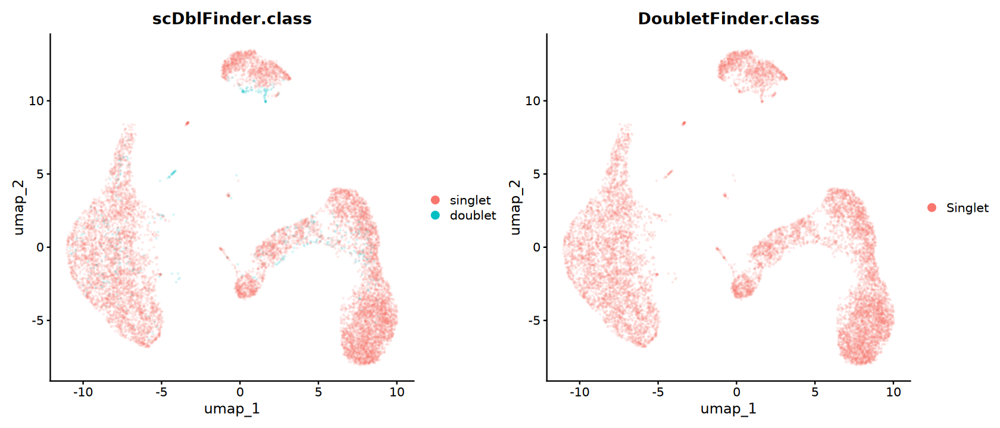

In [40]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(subset(sc.temp, subset = DoubletFinder.class == "Singlet"), 
        reduction = "umap", alpha = 0.1, ncol = 2,
        group.by = c("scDblFinder.class", "DoubletFinder.class"))

In [41]:
scrna <- subset(
    scrna, 
    subset = DoubletFinder.class == "Singlet" & 
        scDblFinder.class == "singlet")
scrna

An object of class Seurat 
22302 features across 10334 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 1 layer present: counts

## Filtering low-quality cells

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(scrna, layer = "counts", 
        features = c("nFeature_RNA", "nCount_RNA", 
                     "percent.mt", "percent.rp", "percent.hb"), 
        pt.size = 0.1, alpha = 0.1, ncol = 5) + 
    NoLegend()

In [ ]:
options(repr.plot.width = 21, repr.plot.height = 6)
FeaturePlot(
    subset(sc.temp, subset = DoubletFinder.class == "Singlet" & 
           scDblFinder.class == "singlet"), 
    reduction = "umap", ncol = 3,
    features = c("nCount_RNA", "nFeature_RNA", "percent.mt"))

In [13]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 500 & percent.mt < 20)
scrna

An object of class Seurat 
22302 features across 11666 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)

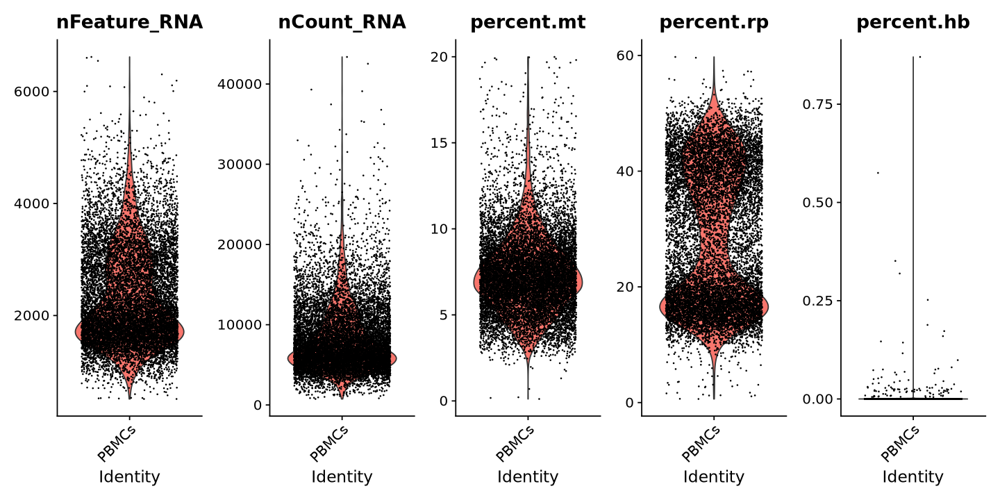

In [14]:
options(repr.plot.width = 12, repr.plot.height = 6)
VlnPlot(scrna, 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt",
                     "percent.rp", "percent.hb"), 
        pt.size = 0.1, ncol = 5) + 
    NoLegend()

# 3. Evaluating Noise

## Cell cycle effect

In [15]:
str(cc.genes)

List of 2
 $ s.genes  : chr [1:43] "MCM5" "PCNA" "TYMS" "FEN1" ...
 $ g2m.genes: chr [1:54] "HMGB2" "CDK1" "NUSAP1" "UBE2C" ...


In [16]:
scrna <- NormalizeData(scrna, verbose = FALSE) |> 
    CellCycleScoring(s.features = cc.genes$s.genes,
                     g2m.features = cc.genes$g2m.genes)

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


## Cell dissociation effect

- van den Brink, S., Sage, F., Vértesy, Á. et al. Single-cell sequencing reveals dissociation-induced gene expression in tissue subpopulations. Nat Methods 14, 935–936 (2017). https://doi.org/10.1038/nmeth.4437

In [17]:
dissociation_genes <- readLines("~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")
str(dissociation_genes)

 chr [1:140] "Actg1" "Btg1" "Cxcl1" "Dnajb4" "Errfi1" "H3f3b" "Hspb1" ...


In [20]:
scrna <- AddModuleScore(
    scrna, name = "Dissociation.Score", 
    features = list(dissociationGenes = toupper(dissociation_genes)))

scrna@meta.data <- scrna@meta.data |> 
    rename("Dis.Score" = "Dissociation.Score1")

Warning message:
“The following features are not present in the object: ANKRD1, CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, NPPC, not searching for symbol synonyms”


## Visualization

In [22]:
sc.temp <- standard_preprocessing(scrna, resolution = 0.5)

Completed LogNormalize workflow.



In [23]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", 
    group.by = c("orig.ident", "Phase", "seurat_clusters"),
    ncol = 3)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", 
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"), 
    ncol = 3)

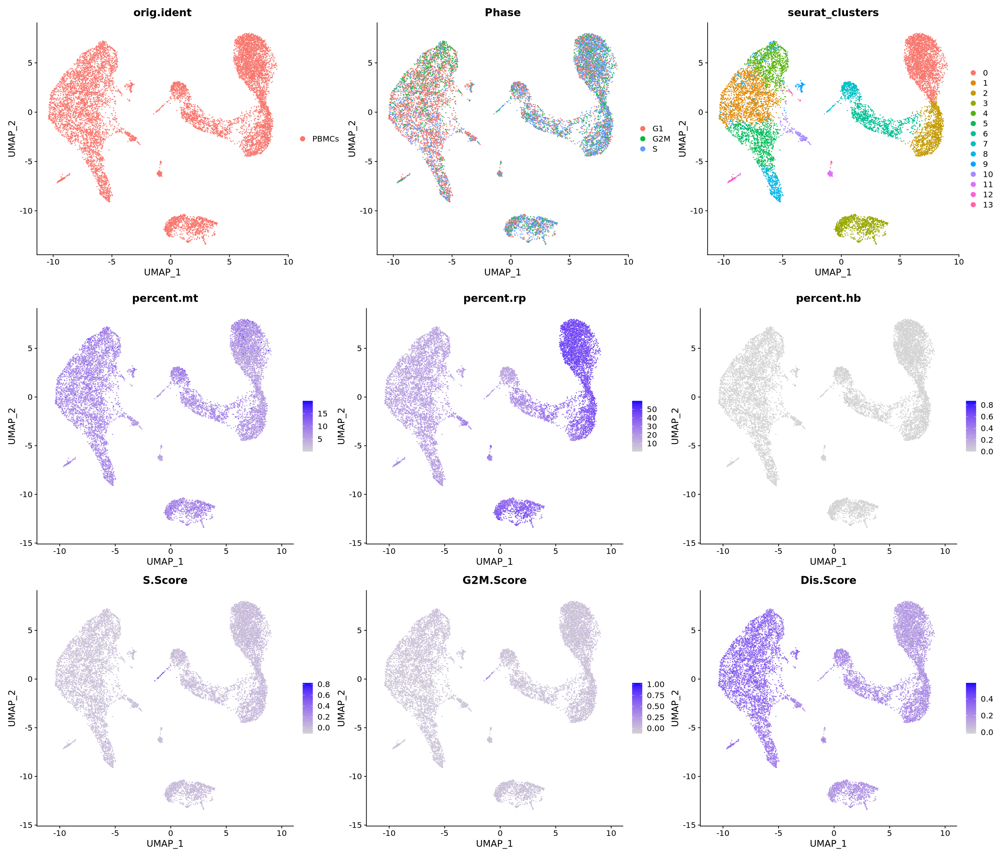

In [24]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(p1, p2, ncol = 1, rel_heights = c(1, 2))

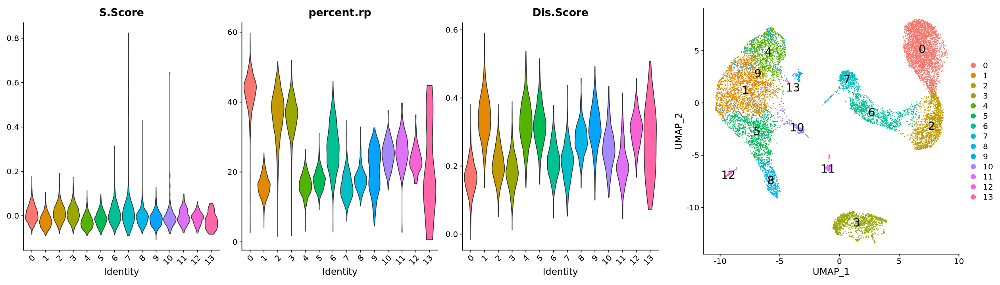

In [25]:
p1 <- VlnPlot(sc.temp, features = c("S.Score", "percent.rp", "Dis.Score"), 
        group.by = "seurat_clusters", pt.size = 0, ncol = 3)
p2 <- DimPlot(sc.temp, reduction = "umap", 
              label = TRUE, label.size = 6)

options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2, rel_widths = c(2, 1))

In [26]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]
scores <- sc.temp@meta.data[, c("S.Score", "G2M.Score",
                                "percent.rp", "Dis.Score")]

cors <- apply(pca, 2, function(pc){
    c(cor(pc, scores$S.Score, method = "pearson"),
      cor(pc, scores$G2M.Score, method = "pearson"),
      cor(pc, scores$percent.rp, method = "pearson"),
      cor(pc, scores$Dis.Score, method = "pearson"))
})

rownames(cors) <- c("cor_S", "cor_G2M", "cor_rp", "cor_Dis")
colnames(cors) <- paste0("PC", 1:ncol(cors))

print(cors)

               PC1          PC2          PC3         PC4         PC5
cor_S   -0.3121926  0.022374761 -0.079706046 -0.02632131 -0.07131725
cor_G2M -0.1573891  0.008070949  0.008467311  0.05984970  0.09960163
cor_rp  -0.7949548  0.108189204  0.370143396  0.14167604 -0.17706050
cor_Dis  0.7820727 -0.098677840 -0.029809289 -0.02906001  0.11640278
                  PC6         PC7          PC8         PC9         PC10
cor_S   -0.0086287455 -0.16672864 -0.160693907 -0.13078487  0.454136901
cor_G2M -0.0626102951 -0.10063345 -0.240458398 -0.17999943  0.452157106
cor_rp   0.0411388625 -0.01991203 -0.007687873  0.10411408 -0.003561587
cor_Dis  0.0002486946 -0.04903586  0.036146835 -0.09908253 -0.068913986


# 4. Normalization

In [27]:
scrna

An object of class Seurat 
22302 features across 11666 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)

## LogNormalize

A global-scaling normalization method “LogNormalize” that normalizes the feature expression measurements for each cell by the total expression, multiplies this by a scale factor (10,000 by default), and log-transforms the result

In [28]:
scrna <- NormalizeData(scrna, verbose = FALSE)
scrna

An object of class Seurat 
22302 features across 11666 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)

In [29]:
scrna <- FindVariableFeatures(scrna, nfeatures = 3000, verbose = FALSE)
scrna

An object of class Seurat 
22302 features across 11666 samples within 1 assay 
Active assay: RNA (22302 features, 3000 variable features)

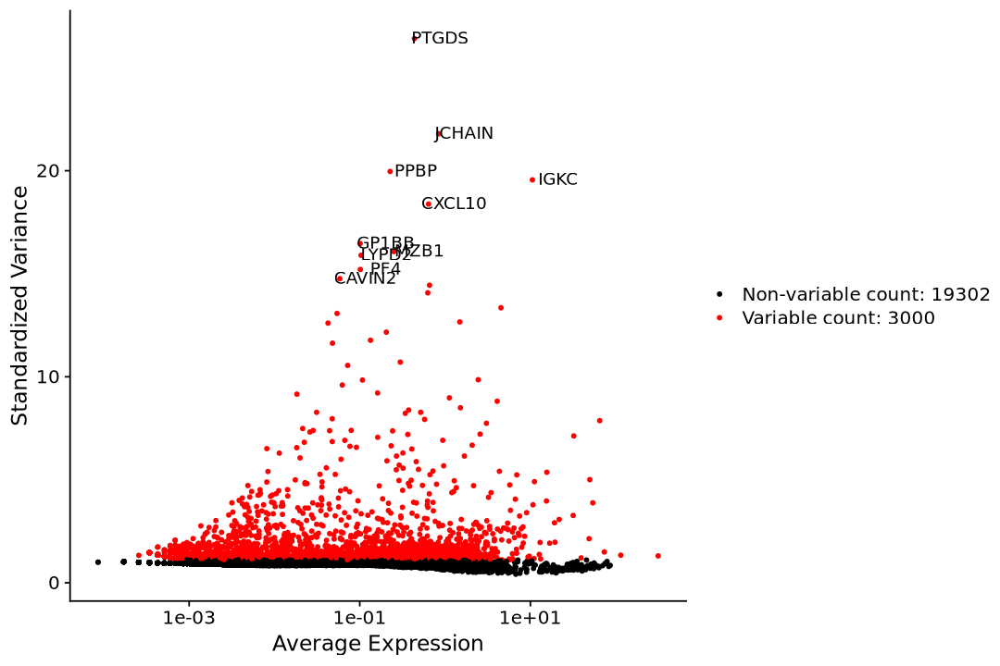

In [49]:
options(repr.plot.width = 9, repr.plot.height = 6)
# plot variable features with and without labels
VariableFeaturePlot(scrna) |> 
    LabelPoints(points = head(VariableFeatures(scrna), 10))

In [46]:
# scrna <- ScaleData(scrna, features = rownames(scrna), 
#                    vars.to.regress = "percent.mt", verbose = FALSE)
scrna <- ScaleData(
    scrna, features = VariableFeatures(scrna), 
    vars.to.regress = "percent.mt", verbose = FALSE)
scrna

An object of class Seurat 
22302 features across 11666 samples within 1 assay 
Active assay: RNA (22302 features, 3000 variable features)

In [ ]:
suppressPackageStartupMessages(library(future))

In [ ]:
options(future.globals.maxSize = 16*1024^3)
plan("multicore", workers = 4) # open multi core
time_taken <- system.time({
    scDat.combined <- ScaleData(scDat.combined, features = Features(scDat.combined), 
                                vars.to.regress = c("percent.mt", "S.Score", "G2M.Score"))
})
plan("sequential") # close multi core
saveRDS(scDat.combined, paste0(outputDir, "/", "scaleData.rds"))
print(time_taken)

## SCTransform

A modeling framework for the normalization and variance stabilization of molecular count data from scRNA-seq experiments. This procedure omits the need for heuristic steps including pseudocount addition or log-transformation and improves common downstream analytical tasks such as variable gene selection, dimensional reduction, and differential expression.

In [57]:
time_taken <- system.time({
    scrna <- SCTransform(scrna, return.only.var.genes = FALSE, 
                         vars.to.regress = c("percent.mt"),
                         verbose = FALSE)
})

scrna

cat("Elapsed:", format(.POSIXct(time_taken["elapsed"], tz = "UTC"), "%H:%M:%S"), "\n")

Warning message:
“The `slot` argument of `SetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


An object of class Seurat 
42433 features across 10309 samples within 2 assays 
Active assay: SCT (20131 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: RNA

Elapsed: 00:01:29 


In [ ]:
# options(future.globals.maxSize = 50*1024^3)
# plan("multisession", workers = 4) # open multi core
# time_taken <- system.time({
#     scDat.combined <- SCTransform(scDat.combined, return.only.var.genes = FALSE,
#                                   vars.to.regress = c("percent.mt", "S.Score", "G2M.Score", "Dissociation.Score"))
# })
# plan("sequential") # close multi core
# saveRDS(scDat.combined, paste0(outputDir, "step03_2_SCTransform.rds"))
# print(time_taken)

In [58]:
DefaultAssay(scrna) <- "RNA"
scrna

An object of class Seurat 
42433 features across 10309 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT

In [59]:
saveRDS(scrna, file.path(data_dir, "result", "s4_seurat_normalization.rds"))

In [3]:
scrna <- readRDS(file.path(data_dir, "result", "s4_seurat_normalization.rds"))

In [59]:
scrna

An object of class Seurat 
42433 features across 10309 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT

# 5. Dimensional Reduction

## PCA

In [50]:
scrna <- RunPCA(
    scrna, features = VariableFeatures(scrna), npcs = 50)

PC_ 1 
Positive:  FGL2, FCN1, LYZ, CST3, CTSS, MNDA, TYMP, CYBB, PSAP, IFI30 
	   SERPINA1, NCF2, LST1, TYROBP, S100A9, AIF1, MPEG1, CSTA, TNFSF13B, TMEM176B 
	   DUSP6, FTL, CD68, GRN, FOS, MS4A6A, IGSF6, AC020656.1, DUSP1, S100A8 
Negative:  LTB, CD3E, IL32, CD3D, TRAC, PCED1B-AS1, TRBC2, CD3G, ETS1, BCL11B 
	   MALAT1, IL7R, LCK, ARL4C, CD2, LBH, LIME1, TCF7, CD7, LINC00861 
	   PRKCQ-AS1, FCMR, CD27, SPOCK2, CCR7, PIK3IP1, CLEC2D, CD247, GZMM, SKAP1 
PC_ 2 
Positive:  MS4A1, CD79A, IGHM, BANK1, CD79B, LINC00926, RALGPS2, NIBAN3, TNFRSF13C, BCL11A 
	   SPIB, IGHD, HLA-DQA1, IGKC, CD22, AFF3, LINC02397, PAX5, VPREB3, FCRL1 
	   CD74, BLK, HLA-DRA, COBLL1, FCER2, TCF4, BLNK, HLA-DRB1, SWAP70, HLA-DPB1 
Negative:  FYB1, IL32, CD3E, CD3D, CD3G, GZMM, CD2, CTSW, ANXA1, CD247 
	   CD7, BCL11B, LCK, TRAC, GZMA, S100A4, NKG7, CST7, LINC00861, PRF1 
	   IL7R, CCL5, GNLY, KLRK1, LAT, KLRD1, ARL4C, SAMD3, TRBC1, TMSB4X 
PC_ 3 
Positive:  CCR7, LEF1, IL7R, TCF7, PIK3IP1, MAL, TRABD2A, RCAN3, NO

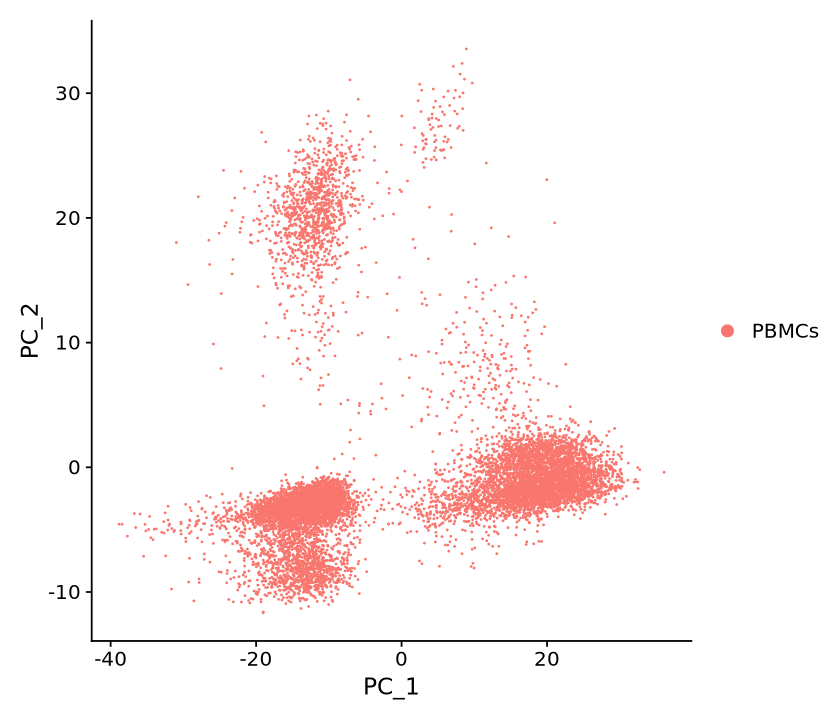

In [51]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(scrna, reduction = "pca")

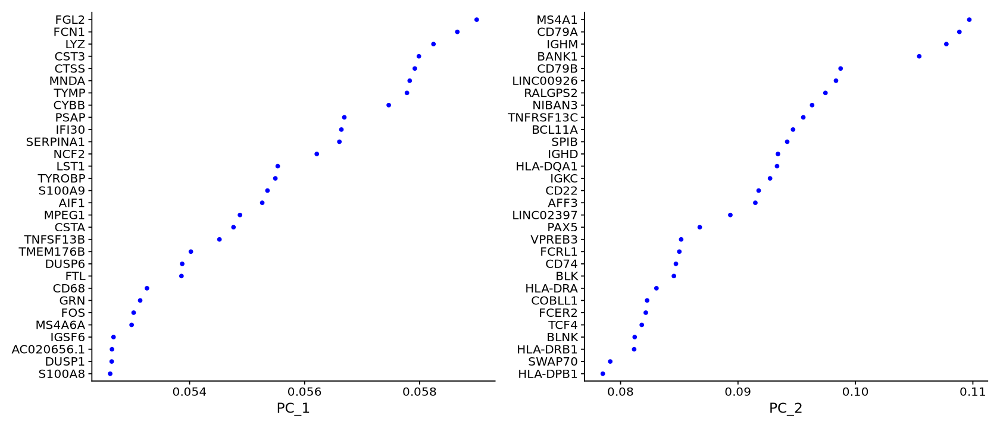

In [52]:
options(repr.plot.width = 14, repr.plot.height = 6)
VizDimLoadings(scrna, dims = 1:2, reduction = "pca", ncol = 2)

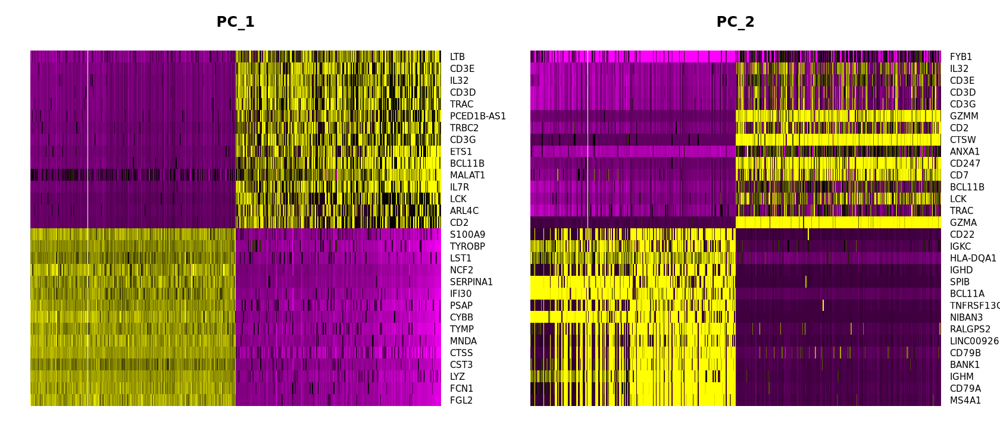

In [53]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimHeatmap(scrna, dims = 1:2, cells = 500, balanced = TRUE)

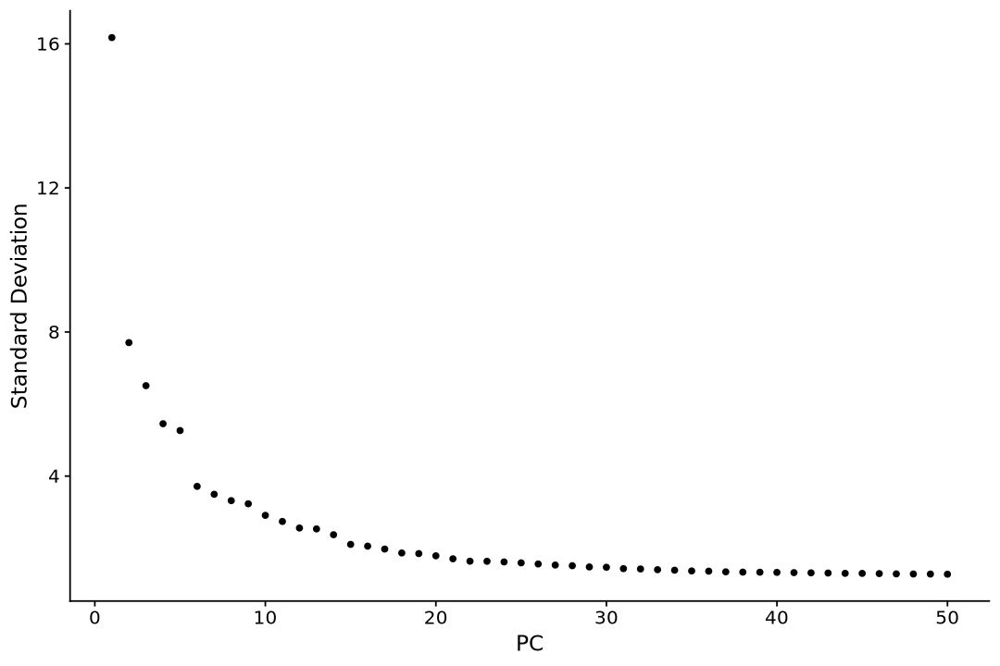

In [54]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(scrna, ndims = 50)

In [55]:
# Estimating PCA dimensionality
pca_var <- scrna@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
pc <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
pc

[1] 21

In [ ]:
scrna <- JackStraw(scrna, num.replicate = 100)
scrna

In [ ]:
scrna <- ScoreJackStraw(scrna, dims = 1:20)
scrna

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
JackStrawPlot(scrna, dims = 1:20)

# 6. Integration (Skip)

# 7. Cluster

In [56]:
nPCs <- 20

In [67]:
scrna <- RunUMAP(scrna, dims = 1:nPCs, reduction = "pca", 
                 verbose = FALSE)
scrna <- RunTSNE(scrna, dims = 1:nPCs, reduction = "pca", 
                 verbose = FALSE)
scrna

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


An object of class Seurat 
42433 features across 10309 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, umap, tsne

In [68]:
scrna <- FindNeighbors(scrna, features = VariableFeatures(scrna),
                       reduction = "pca", dims = 1:nPCs,  verbose = FALSE)
scrna

An object of class Seurat 
42433 features across 10309 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, umap, tsne

In [69]:
suppressPackageStartupMessages(library(clustree))

In [70]:
resolution_clusters <- function (
    seurat, plot_dir, reduction, nPCs = 10, resolution = seq(0.1, 1, 0.1)) {

    for (res in resolution) {
        seurat <- FindClusters(seurat, resolution = res, verbose = FALSE)
        # UMAP
        seurat <- RunUMAP(seurat, dims = 1:nPCs, 
                          reduction = reduction, verbose = FALSE)
        p <- DimPlot(seurat, reduction = "umap", group.by = c("seurat_clusters"), 
                     label = TRUE, label.size = 6, repel = TRUE)
        file.path(plot_dir, paste0("p7.1_UMAP_clusters_", res ,".png")) |>
            ggsave(plot = p, width = 7, height = 6)
        # t-SNE
        seurat <- RunTSNE(seurat, dims = 1:nPCs, 
                          reduction = reduction, verbose = FALSE)
        p <- DimPlot(seurat, reduction = "tsne", group.by = c("seurat_clusters"),
                     label = TRUE, label.size = 6, repel = TRUE)
        file.path(plot_dir, paste0("p7.2_TSNE_clusters_", res ,".png")) |>
            ggsave(plot = p, width = 7, height = 6)
    }
    
    cluster_tree <- clustree(seurat@meta.data, prefix = "RNA_snn_res.", 
                             node_text_size = 6) +
        theme(legend.title = element_text(size = 18), 
              legend.text = element_text(size = 16))
    
    file.path(plot_dir, paste0("p7.3_cluster_tree.png")) |>
        ggsave(plot = cluster_tree, width = 12, height = 10)
    
    return(cluster_tree)
}

In [71]:
cluster_tree <- resolution_clusters(
    scrna, plot_dir = file.path(data_dir, "visualization"),
    reduction = "pca", nPCs = nPCs, 
    resolution = seq(0.1, 1, 0.1)
)

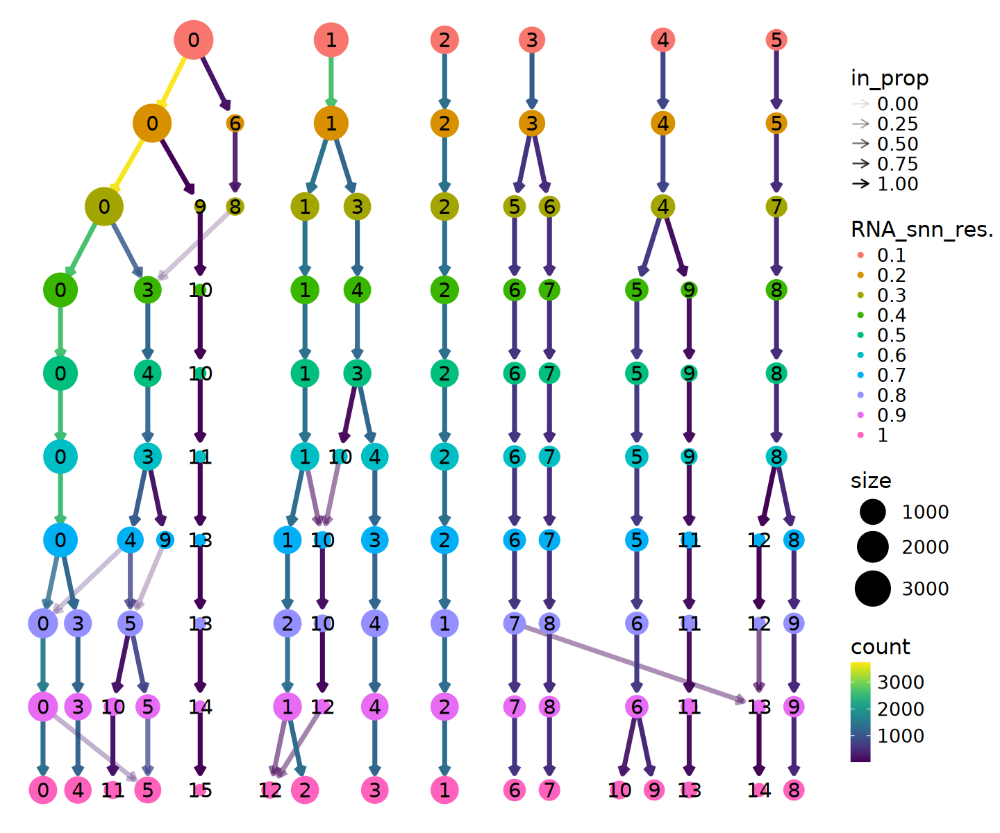

In [72]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_tree

### Select resolution

In [73]:
scrna <- FindClusters(scrna, resolution = 0.5, 
                      verbose = FALSE)
scrna <- RunUMAP(scrna, dims = 1:nPCs, reduction = "pca", 
                 verbose = FALSE)
scrna <- RunTSNE(scrna, dims = 1:nPCs, reduction = "pca",
                 verbose = FALSE)
scrna

An object of class Seurat 
42433 features across 10309 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, umap, tsne

In [74]:
p1 <- DimPlot(scrna, reduction = "umap", group.by = "seurat_clusters", 
              label = TRUE, label.size = 6, repel = TRUE)
p2 <- DimPlot(scrna, reduction = "tsne", group.by = "seurat_clusters", 
              label = TRUE, label.size = 6, repel = TRUE)

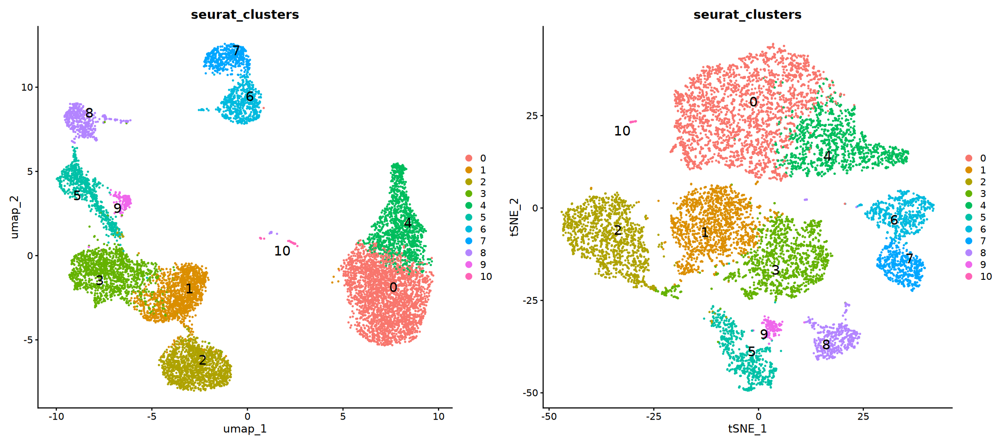

In [75]:
options(repr.plot.width = 18, repr.plot.height = 8)
plot_grid(p1, p2, ncol = 2)

In [76]:
scrna

An object of class Seurat 
42433 features across 10309 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, umap, tsne

In [77]:
# Silhouette Coefficiency
calc_silhouette <- function(
    seurat, reduction = "pca", nPCs = 10, cluster_col = "seurat_clusters") {
    
    clus <- scrna@meta.data[, cluster_col] |> as.integer()
    
    pca_dist <- Embeddings(scrna, reduction)[, 1:nPCs] |> dist()
    sil_mat <- cluster::silhouette(clus, pca_dist)
    mean(sil_mat[, 3])                               
}

In [79]:
calc_silhouette(scrna, reduction = "PCA", nPCs = nPCs)

ERROR: [1m[33mError[39m in `object[[reduction]]`:[22m
[33m![39m ‘PCA’ not found in this Seurat object
 


In [ ]:
# Modularity
calc_modularity <- function(
    seurat, graph_name = "RNA_snn", cluster_col = "seurat_clusters",
    sample_threshold = 20000, sample_size = 10000) {

    if (ncol(seurat) > sample_threshold) {
        message(sprintf(
            "⚠️ Detected %d cells > %d. Sampling %d cells for modularity calculation...",
            ncol(seurat), sample_threshold, sample_size
        ))
        sampled_cells <- sample(colnames(seurat), sample_size)
        seurat <- subset(seurat, cells = sampled_cells)
    }
    
    clus <- seurat@meta.data[, cluster_col] |> as.integer()
    
    seurat@graphs[[graph_name]] |> as.matrix() |>
        igraph::graph_from_adjacency_matrix(
            mode = "undirected", weighted = TRUE) |>
        igraph::modularity(clus)
}

In [ ]:
calc_modularity(scrna)

In [ ]:
mean_cluster_logfc <- function(
    seurat, min.pct = 0.25, logfc.threshold = 0.25, top_n = 10) {
    
    FindAllMarkers(seurat, logfc.threshold = logfc.threshold, min.pct = min.pct,
                   only.pos = TRUE, verbose = FALSE) |>
        group_by(cluster) |>
        top_n(n = top_n, wt = avg_log2FC) |>
        summarise(med = median(avg_log2FC)) |>
        summarise(mean_median_logFC = mean(med)) |>
        pull(mean_median_logFC)
}

In [ ]:
mean_cluster_logfc(scrna)

# 8. Find marker genes

In [97]:
time_taken <- system.time({
    sc.markers <- FindAllMarkers(scrna, logfc.threshold = 0.25, min.pct = 0.1,
                                 only.pos = FALSE, verbose = FALSE)
})

cat("Elapsed:", format(.POSIXct(time_taken["elapsed"], tz = "UTC"), "%H:%M:%S"), "\n")

Elapsed: 00:00:58 


In [98]:
head(sc.markers)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
S100A12,0,5.278460,0.977,0.115,0,0,S100A12
VCAN,0,4.605997,0.995,0.165,0,0,VCAN
CD14,0,3.714955,0.970,0.141,0,0,CD14
AC020656.1,0,3.527201,0.985,0.171,0,0,AC020656.1
MS4A6A,0,2.991767,0.981,0.168,0,0,MS4A6A
CSTA,0,3.254149,0.980,0.169,0,0,CSTA


In [100]:
p1 <- VlnPlot(scrna, features = "CD14")
p2 <- RidgePlot(scrna, features = "CD14")
p3 <- FeaturePlot(scrna, reduction = "umap", features = "CD14")

Picking joint bandwidth of 0.0638



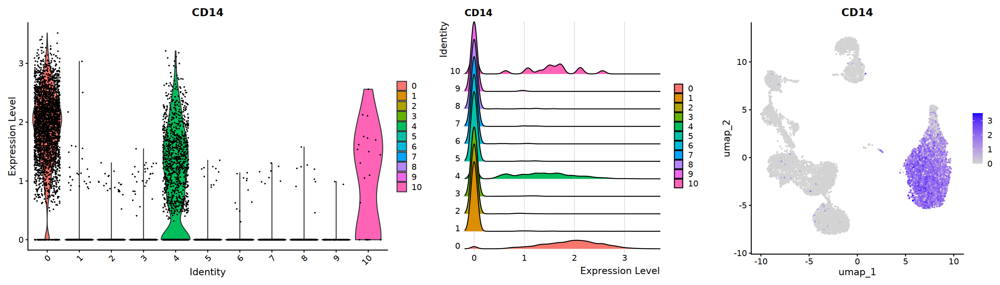

In [101]:
options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(p1, p2, p3, ncol = 3, rel_widths = c(1.5, 1, 1))

In [102]:
sc.markers |> group_by(cluster) |> 
    dplyr::filter(avg_log2FC > 1) |> 
    dplyr::filter(p_val < 0.05) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10
length(gene),1602,207,197,250,1038,404,451,486,940,361,870


In [105]:
top10 <- sc.markers |> 
    group_by(cluster) |> 
    dplyr::filter(avg_log2FC > 1) |> 
    dplyr::filter(p_val < 0.05) |> 
    top_n(10, wt = avg_log2FC)

top5 <- sc.markers |> 
    group_by(cluster) |> 
    dplyr::filter(avg_log2FC > 1) |> 
    dplyr::filter(p_val < 0.05) |> 
    top_n(5, wt = avg_log2FC)

## Visualization

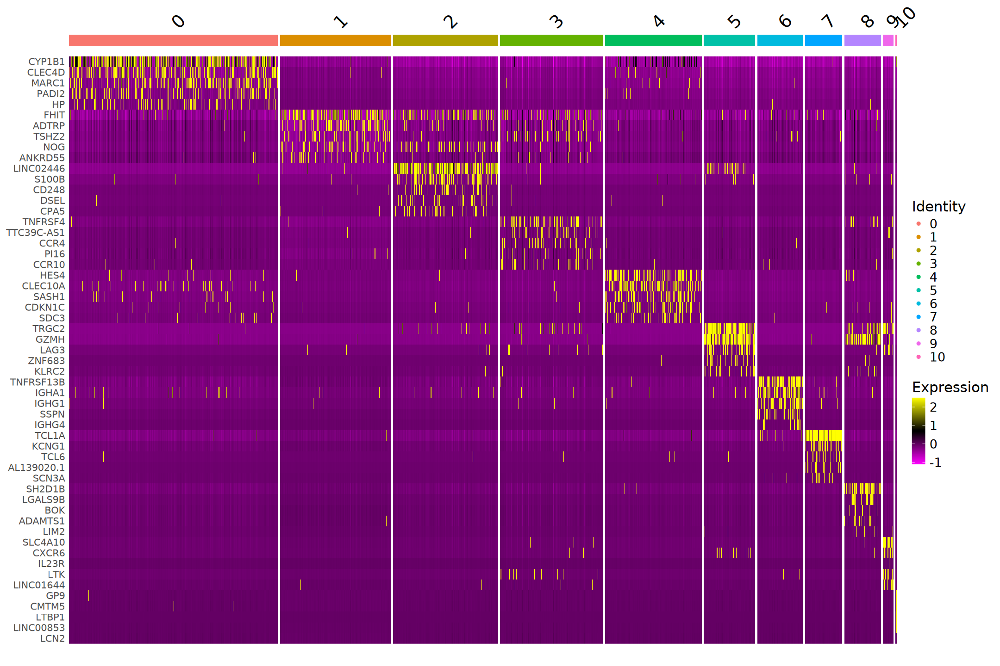

In [117]:
options(repr.plot.width = 18, repr.plot.height = 12)
DoHeatmap(scrna, features = top5$gene, size = 8) +
    # scale_fill_gradientn(colors = PurpleAndYellow()) +
    theme(axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

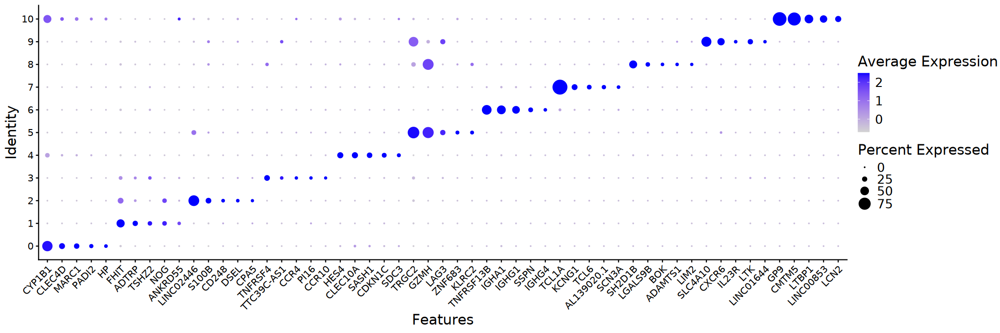

In [127]:
options(repr.plot.width = 18, repr.plot.height = 6)
DotPlot(scrna, features = top5$gene, dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [129]:
for (index in seq(1:length(top10$gene))) {
    plot_dir <- file.path(
        data_dir, "visualization", "p8.2_cluster_top10_genes",
        paste0("cluster_", top10$cluster[index]))
    
    if (!dir.exists(plot_dir)) {
        dir.create(plot_dir, recursive = TRUE)
    }
    
    p <- FeaturePlot(scrna, reduction = "umap", 
                     features = top10$gene[index])
    file.path(plot_dir, paste0("umap_", top10$gene[index], ".png")) |>
        ggsave(plot = p, width = 7, height = 6)
    
    p <- FeaturePlot(scrna, reduction = "tsne", 
                     features = top10$gene[index])
    file.path(plot_dir, paste0("tsne_", top10$gene[index], ".png")) |>
        ggsave(plot = p, width = 7, height = 6)
}

# 9. Annotation

## Automated

### [ScType](https://github.com/IanevskiAleksandr/sc-type/)

ScType: Fully-automated and ultra-fast cell-type identification using specific marker combinations from single-cell transcriptomic data

- Ianevski, A., Giri, A.K. & Aittokallio, T. Fully-automated and ultra-fast cell-type identification using specific marker combinations from single-cell transcriptomic data. Nat Commun 13, 1246 (2022). https://doi.org/10.1038/s41467-022-28803-w

In [192]:
source("https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/R/sctype_wrapper.R")
db_ <- "https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/ScTypeDB_full.xlsx"
db_ <- "https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/ScTypeDB_short.xlsx"

sc.temp <- run_sctype(
    scrna, assay = "RNA", scaled = TRUE, known_tissue_type = "Immune system",
    custom_marker_file = db_, name = "sctype_classification")


Warning message in file(filename, "r", encoding = encoding):
“URL 'https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/R/auto_detect_tissue_type.R': Timeout of 60 seconds was reached”


ERROR: Error in file(filename, "r", encoding = encoding): cannot open the connection to 'https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/R/auto_detect_tissue_type.R'


In [194]:
suppressPackageStartupMessages(library(openxlsx))
suppressPackageStartupMessages(library(HGNChelper))

In [ ]:
# load gene set preparation function
source("https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/R/gene_sets_prepare.R")
# load cell type annotation function
source("https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/R/sctype_score_.R")

# get cell-type-specific gene sets from our in-built database (DB)
db_ <- "https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/ScTypeDB_full.xlsx"
db_ <- "https://raw.githubusercontent.com/IanevskiAleksandr/sc-type/master/ScTypeDB_short.xlsx"

In [ ]:
# check Seurat object version (scRNA-seq matrix extracted differently in Seurat v4/v5)
seurat_package_v5 <- isFALSE('counts' %in% names(attributes(pbmc[["RNA"]])));
print(sprintf("Seurat object %s is used", ifelse(seurat_package_v5, "v5", "v4")))

# extract scaled scRNA-seq matrix
scRNAseqData_scaled <- if (seurat_package_v5) as.matrix(pbmc[["RNA"]]$scale.data) else as.matrix(pbmc[["RNA"]]@scale.data)

# run ScType
es.max <- sctype_score(scRNAseqData = scRNAseqData_scaled, scaled = TRUE, gs = gs_list$gs_positive, gs2 = gs_list$gs_negative)

# NOTE: scRNAseqData parameter should correspond to your input scRNA-seq matrix. For raw (unscaled) count matrix set scaled = FALSE
# When using Seurat, we use "RNA" slot with 'scale.data' by default. Please change "RNA" to "SCT" for sctransform-normalized data,
# or to "integrated" for joint dataset analysis. To apply sctype with unscaled data, use e.g. pbmc[["RNA"]]$counts or pbmc[["RNA"]]@counts, with scaled set to FALSE.

# merge by cluster
cL_resutls <- do.call("rbind", lapply(unique(pbmc@meta.data$seurat_clusters), function(cl){
    es.max.cl = sort(rowSums(es.max[ ,rownames(pbmc@meta.data[pbmc@meta.data$seurat_clusters==cl, ])]), decreasing = !0)
    head(data.frame(cluster = cl, type = names(es.max.cl), scores = es.max.cl, ncells = sum(pbmc@meta.data$seurat_clusters==cl)), 10)
}))
sctype_scores <- cL_resutls %>% group_by(cluster) %>% top_n(n = 1, wt = scores)  

# set low-confident (low ScType score) clusters to "unknown"
sctype_scores$type[as.numeric(as.character(sctype_scores$scores)) < sctype_scores$ncells/4] <- "Unknown"
print(sctype_scores[,1:3])

In [ ]:
pbmc@meta.data$sctype_classification = ""
for(j in unique(sctype_scores$cluster)){
  cl_type = sctype_scores[sctype_scores$cluster==j,]; 
  pbmc@meta.data$sctype_classification[pbmc@meta.data$seurat_clusters == j] = as.character(cl_type$type[1])
}

DimPlot(pbmc, reduction = "umap", label = TRUE, repel = TRUE, group.by = 'sctype_classification')        


In [ ]:
# load libraries
lapply(c("ggraph","igraph","tidyverse", "data.tree"), library, character.only = T)

# prepare edges
cL_resutls <- cL_resutls[order(cL_resutls$cluster),]; edges = cL_resutls; edges$type = paste0(edges$type,"_",edges$cluster); edges$cluster = paste0("cluster ", edges$cluster); edges = edges[,c("cluster", "type")]; colnames(edges) = c("from", "to"); rownames(edges) <- NULL

# prepare nodes
nodes_lvl1 <- sctype_scores[,c("cluster", "ncells")]; nodes_lvl1$cluster = paste0("cluster ", nodes_lvl1$cluster); nodes_lvl1$Colour = "#f1f1ef"; nodes_lvl1$ord = 1; nodes_lvl1$realname = nodes_lvl1$cluster; nodes_lvl1 = as.data.frame(nodes_lvl1); nodes_lvl2 = c(); 
ccolss <- c("#5f75ae","#92bbb8","#64a841","#e5486e","#de8e06","#eccf5a","#b5aa0f","#e4b680","#7ba39d","#b15928","#ffff99", "#6a3d9a","#cab2d6","#ff7f00","#fdbf6f","#e31a1c","#fb9a99","#33a02c","#b2df8a","#1f78b4","#a6cee3")
for (i in 1:length(unique(cL_resutls$cluster))){
  dt_tmp = cL_resutls[cL_resutls$cluster == unique(cL_resutls$cluster)[i], ]; nodes_lvl2 = rbind(nodes_lvl2, data.frame(cluster = paste0(dt_tmp$type,"_",dt_tmp$cluster), ncells = dt_tmp$scores, Colour = ccolss[i], ord = 2, realname = dt_tmp$type))
}
nodes <- rbind(nodes_lvl1, nodes_lvl2); nodes$ncells[nodes$ncells<1] = 1;
files_db <- openxlsx::read.xlsx(db_)[,c("cellName","shortName")]; files_db = unique(files_db); nodes = merge(nodes, files_db, all.x = T, all.y = F, by.x = "realname", by.y = "cellName", sort = F)
nodes$shortName[is.na(nodes$shortName)] = nodes$realname[is.na(nodes$shortName)]; nodes = nodes[,c("cluster", "ncells", "Colour", "ord", "shortName", "realname")]

mygraph <- graph_from_data_frame(edges, vertices=nodes)

# Make the graph
gggr <- ggraph(mygraph, layout = 'circlepack', weight=I(ncells)) + 
  geom_node_circle(aes(filter=ord==1,fill=I("#F5F5F5"), colour=I("#D3D3D3")), alpha=0.9) + geom_node_circle(aes(filter=ord==2,fill=I(Colour), colour=I("#D3D3D3")), alpha=0.9) +
  theme_void() + geom_node_text(aes(filter=ord==2, label=shortName, colour=I("#ffffff"), fill="white", repel = !1, parse = T, size = I(log(ncells,25)*1.5)))+ geom_node_label(aes(filter=ord==1,  label=shortName, colour=I("#000000"), size = I(3), fill="white", parse = T), repel = !0, segment.linetype="dotted")
  
DimPlot(pbmc, reduction = "umap", label = TRUE, repel = TRUE, cols = ccolss)+ gggr

## Manual

### Marker genes

### Typical genes

Picking joint bandwidth of 0.197

Picking joint bandwidth of 0.0175

Picking joint bandwidth of 0.0115

Picking joint bandwidth of 0.0557

Picking joint bandwidth of 0.0405

Picking joint bandwidth of 0.0911



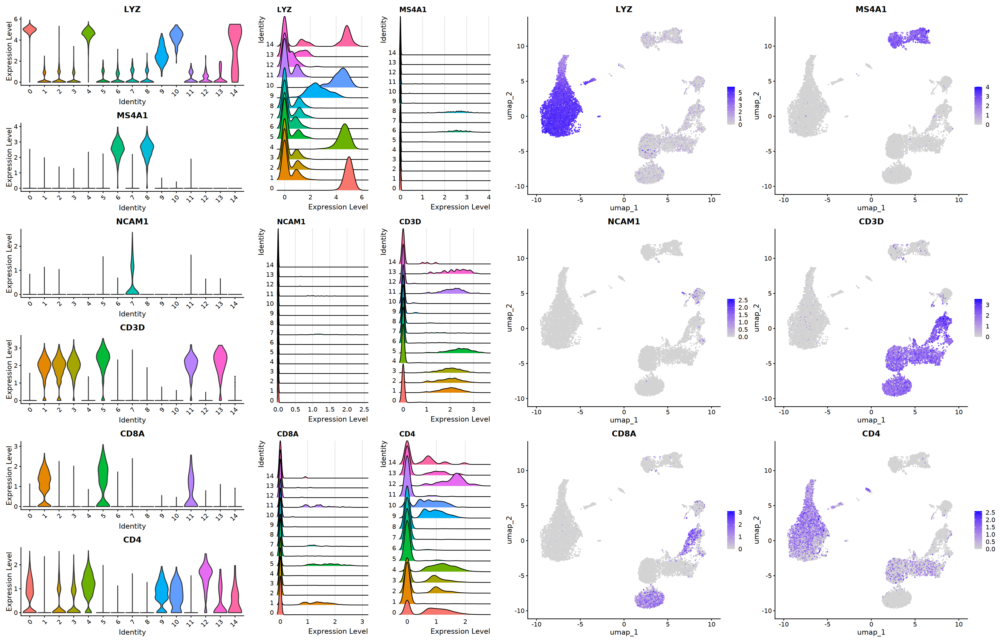

In [106]:
geneset <- c("LYZ", "MS4A1", "NCAM1", "CD3D", "CD8A", "CD4")
p1 <- VlnPlot(
    scrna, features = geneset, ncol = 1, pt.size = 0)
p2 <- RidgePlot(
    scrna, features = geneset, ncol = 2)
p3 <- FeaturePlot(
    scrna, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 28, repr.plot.height = 18)
plot_grid(p1, p2, p3, ncol = 3, rel_widths = c(1, 1, 2))

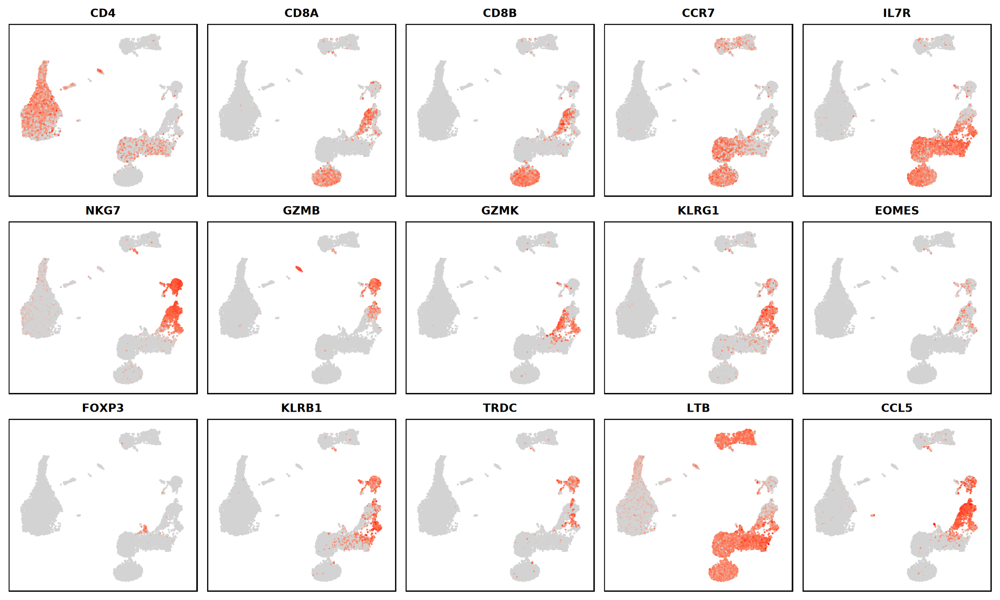

In [107]:
geneset <- c("CD4", "CD8A", "CD8B", "CCR7", "IL7R", 
             "NKG7", "GZMB", "GZMK", "KLRG1", "EOMES", 
             "FOXP3", "KLRB1", "TRDC", "LTB", "CCL5")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

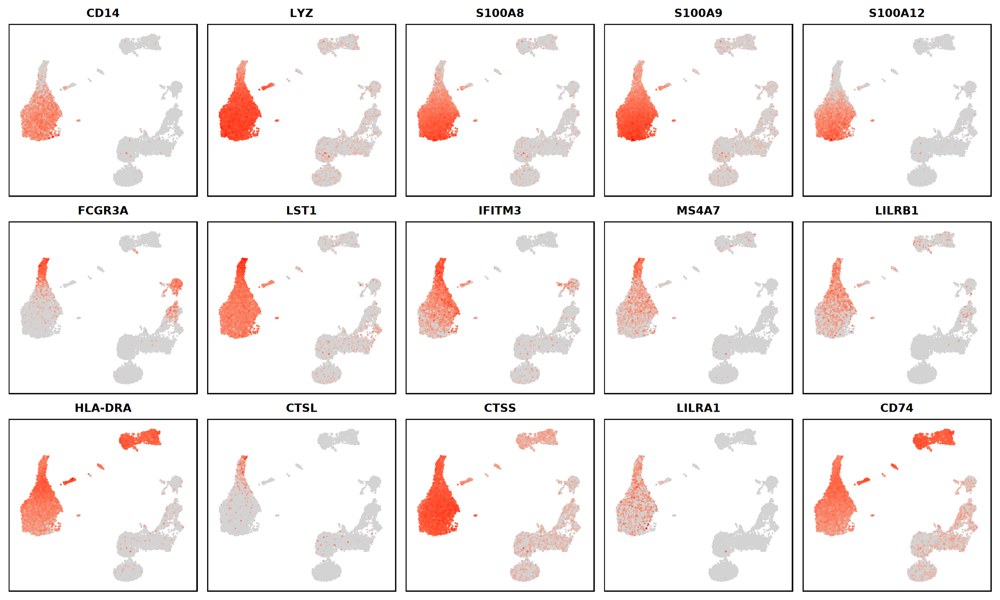

In [108]:
# Classical monocytes: "CD14", "LYZ", "S100A8", "S100A9", "S100A12"
# Non-classical monocytes: "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1"
# Intermediate monocytes: "CD14", "FCGR3A", "HLA-DRA", "HLA-DPB1", "CTSL", "CTSS", "LILRA1", "CD74"

geneset <- c("CD14", "LYZ", "S100A8", "S100A9", "S100A12",
             "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1",
             "HLA-DRA", "CTSL", "CTSS", "LILRA1", "CD74")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

Warning message:
“The following requested variables were not found: PTLRA”


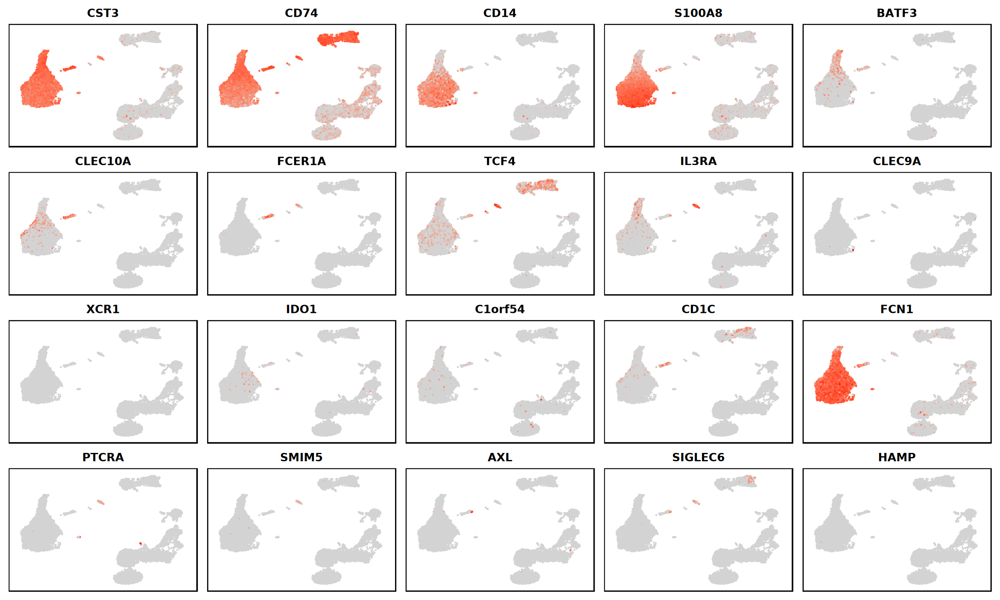

In [111]:
# cDC1: "CLEC9A", "XCR1", "IDO1", "C1orf54"
# cDC2: "CD1C", "FCN1", "PILRA"
# pDC: "PTCRA", "SMIM5"
# ASDC: "AXL", "SIGLEC6", "HAMP"

geneset <- c("CST3", "CD74", "BATF3", 
             "CLEC10A", "FCER1A", "TCF4", "IL3RA",
             "CLEC9A", "XCR1", "IDO1", "C1orf54",
             "CD1C", "FCN1", "PTLRA", 
             "PTCRA", "SMIM5",
             "AXL", "SIGLEC6", "HAMP")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

In [109]:
suppressPackageStartupMessages(library(SeuratDisk))

In [110]:
output_dir <- file.path(
    data_dir, "result", "s11_annotation_seurat_V5.h5Seurat")
SaveH5Seurat(scrna, filename = output_dir, verbose = FALSE)

Creating h5Seurat file for version 3.1.5.9900



In [ ]:
suppressPackageStartupMessages(library("Nebulosa"))

In [ ]:
options(repr.plot.width = 21, repr.plot.height = 6)
plot_density(sc.inte, c("CD4", "CCR7"), joint = TRUE)